In [ ]:
!pip install ultralytics opencv-python-headless


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.3 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
import zipfile

# Update this file name if your ZIP name is different in Drive
zip_path = "/content/drive/MyDrive/License Plate Project.v1i.yolov8.zip"
extract_path = "/content/lpr_dataset"

if not os.path.exists(zip_path):
    raise FileNotFoundError(f"ZIP file not found: {zip_path}")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted at:", extract_path)


Extracted at: /content/lpr_dataset


In [ ]:
for root, dirs, files in os.walk("/content/lpr_dataset"):
    print(root)


/content/lpr_dataset
/content/lpr_dataset/train
/content/lpr_dataset/train/labels
/content/lpr_dataset/train/images
/content/lpr_dataset/test
/content/lpr_dataset/test/labels
/content/lpr_dataset/test/images
/content/lpr_dataset/valid
/content/lpr_dataset/valid/labels
/content/lpr_dataset/valid/images


In [ ]:
yaml = """
path: /content/lpr_dataset
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['plate']
"""

with open("/content/lpr.yaml", "w") as f:
    f.write(yaml)

print(open("/content/lpr.yaml").read())



path: /content/lpr_dataset
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['plate']



In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # use nano model

model.train(
    data="/content/lpr.yaml",
    epochs=50,
    imgsz=380,
    batch=32,
    name="lp_detector",
    project="/content/runs"
)


Ultralytics 8.4.27 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lpr.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=380, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=lp_detector2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ac6209258e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/lp_detector2/weights/best.pt")

model.predict(
    source="/content/lpr_dataset/test/images",
    save=True,
    imgsz=640,
    conf=0.25
)



image 1/978 /content/lpr_dataset/test/images/0002a5b67e5f0909_jpg.rf.300ba325f1e5e11ec6fdb10e70d11f4b.jpg: 640x640 2 plates, 10.5ms
image 2/978 /content/lpr_dataset/test/images/000812dcf304a8e7_jpg.rf.f0b445cb199333b34743798d98cdb57b.jpg: 640x640 1 plate, 10.0ms
image 3/978 /content/lpr_dataset/test/images/0010f4c10f7ab07e_jpg.rf.6aa0a7fccae068586c77cd9b3a165cbb.jpg: 640x640 1 plate, 9.1ms
image 4/978 /content/lpr_dataset/test/images/001cdd25e148cd36_jpg.rf.c59f608edbeada6b32926d693afa4c74.jpg: 640x640 1 plate, 7.5ms
image 5/978 /content/lpr_dataset/test/images/002519f868563098_jpg.rf.747ddee18711caaf4eec8c2788f18a53.jpg: 640x640 1 plate, 7.4ms
image 6/978 /content/lpr_dataset/test/images/0026c246d5c33bea_jpg.rf.5e4c872c6b719cf9461250e4a548bbcf.jpg: 640x640 2 plates, 9.5ms
image 7/978 /content/lpr_dataset/test/images/002901d9d194c4fb_jpg.rf.abb32cb00d3bfe6ccdd63b347f757453.jpg: 640x640 1 plate, 8.6ms
image 8/978 /content/lpr_dataset/test/images/002d099996f3f443_jpg.rf.9dbeeab320aba115

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'plate'}
 obb: None
 orig_img: array([[[ 51,  79,  66],
         [ 40,  68,  55],
         [ 31,  57,  44],
         ...,
         [223, 213, 195],
         [223, 213, 195],
         [223, 213, 195]],
 
        [[ 46,  74,  61],
         [ 43,  71,  58],
         [ 41,  67,  54],
         ...,
         [223, 213, 195],
         [223, 213, 195],
         [223, 213, 195]],
 
        [[ 45,  71,  58],
         [ 52,  78,  65],
         [ 56,  81,  67],
         ...,
         [223, 213, 195],
         [223, 213, 195],
         [223, 213, 195]],
 
        ...,
 
        [[ 77,  85,  85],
         [ 77,  85,  85],
         [ 79,  84,  85],
         ...,
         [176, 172, 167],
         [176, 172, 167],
         [175, 171, 166]],
 
        [[ 84,  89,  90],
         [ 84,  89,  90],
         [ 82,  88,  87],
         ...,
         [176, 172,

Ultralytics 8.4.27 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1178.0±361.8 MB/s, size: 38.8 KB)
val: Scanning /content/lpr_dataset/valid/labels.cache... 1973 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1973/1973 551.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 124/124 6.3it/s 19.6s
                   all       1973       2059      0.943      0.927       0.95      0.675
Speed: 1.4ms preprocess, 3.7ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val
PERFORMANCE METRICS
F1 Score: 0.9347
Recall: 0.9269
Accuracy: 0.9502
Precision: 0.9427
FPR: 0.0573


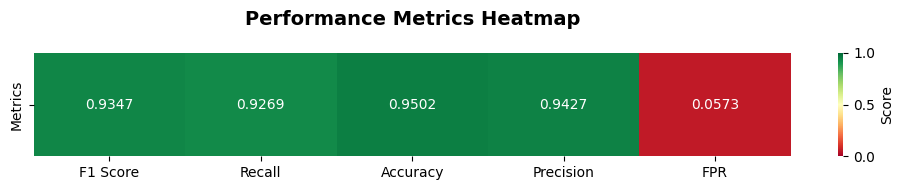

In [ ]:
!pip install seaborn -q

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from ultralytics import YOLO

# Load the trained model
model = YOLO("/content/runs/lp_detector2/weights/best.pt")

# Validate the model to get metrics
results = model.val(data="/content/lpr.yaml", imgsz=640, conf=0.25)

# Extract metrics from results
metrics_dict = results.results_dict

# Get the metrics (try different possible key formats)
# For YOLO v8, metrics keys might vary
precision = (metrics_dict.get('metrics/precision(B)', 0.0) or
             metrics_dict.get('metrics/precision', 0.0) or
             getattr(results, 'box', {}).get('p', 0.0) if hasattr(results, 'box') else 0.0)

recall = (metrics_dict.get('metrics/recall(B)', 0.0) or
          metrics_dict.get('metrics/recall', 0.0) or
          getattr(results, 'box', {}).get('r', 0.0) if hasattr(results, 'box') else 0.0)

f1_score = (metrics_dict.get('metrics/f1(B)', 0.0) or
            metrics_dict.get('metrics/f1', 0.0) or
            (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0)

mAP50 = (metrics_dict.get('metrics/mAP50(B)', 0.0) or
         metrics_dict.get('metrics/mAP50', 0.0) or
         getattr(results, 'box', {}).get('map50', 0.0) if hasattr(results, 'box') else 0.0)

# Use mAP50 as accuracy metric for object detection
accuracy = mAP50

# Calculate FPR (False Positive Rate) = FP / (FP + TN)
# FPR ≈ 1 - precision (for detection tasks)
fpr = 1 - precision if precision > 0 else 0.0

# Create metrics dictionary
metrics = {
    'F1 Score': f1_score,
    'Recall': recall,
    'Accuracy': accuracy,
    'Precision': precision,
    'FPR': fpr
}

# Print metrics separately
print("=" * 50)
print("PERFORMANCE METRICS")
print("=" * 50)
for metric_name, metric_value in metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")
print("=" * 50)

# Create a heatmap
metrics_array = np.array([[metrics['F1 Score'], metrics['Recall'], metrics['Accuracy'],
                          metrics['Precision'], metrics['FPR']]])

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 2))

# Create heatmap
sns.heatmap(metrics_array,
            annot=True,
            fmt='.4f',
            cmap='RdYlGn',
            xticklabels=['F1 Score', 'Recall', 'Accuracy', 'Precision', 'FPR'],
            yticklabels=['Metrics'],
            cbar_kws={'label': 'Score'},
            vmin=0,
            vmax=1,
            ax=ax)

# Set title
ax.set_title('Performance Metrics Heatmap', fontsize=14, fontweight='bold', pad=20)

# Adjust layout
plt.tight_layout()
plt.show()


Please select a vehicle image to test:


Saving WhatsApp Image 2026-03-26 at 6.23.33 PM (1).jpeg to WhatsApp Image 2026-03-26 at 6.23.33 PM (1).jpeg

Testing image: WhatsApp Image 2026-03-26 at 6.23.33 PM (1).jpeg

image 1/1 /content/WhatsApp Image 2026-03-26 at 6.23.33 PM (1).jpeg: 480x640 2 plates, 11.3ms
Speed: 2.3ms preprocess, 11.3ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict20


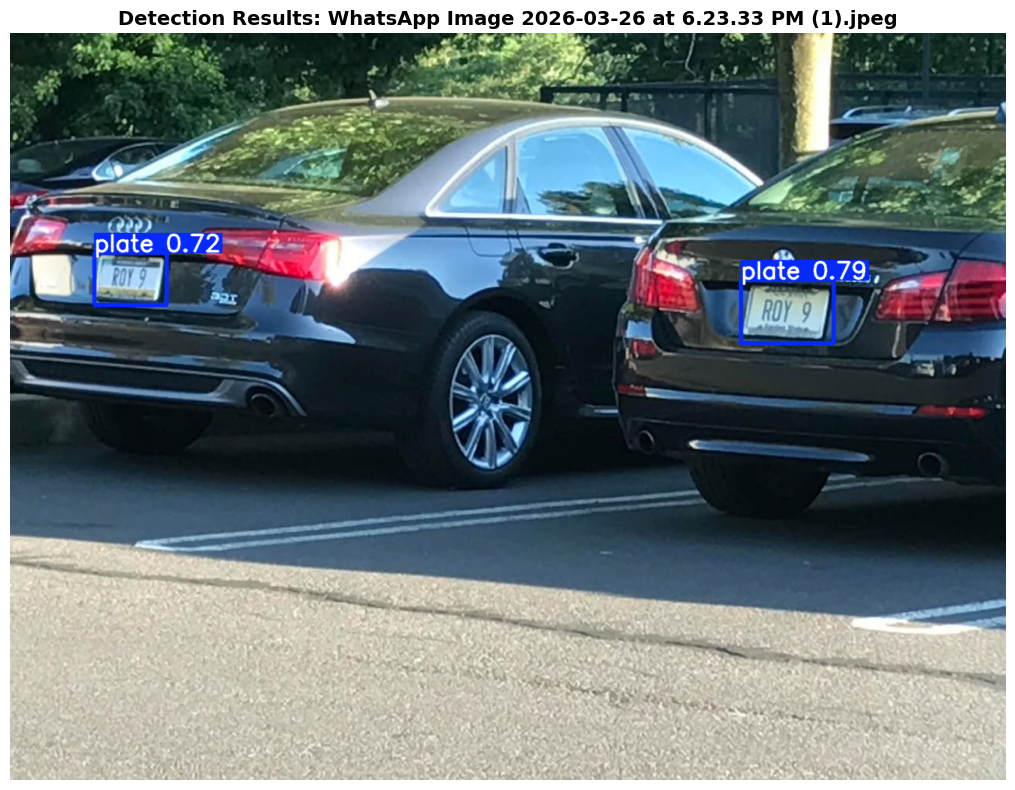


DETECTION RESULTS
Detection 1:
  Class: plate
  Confidence: 0.7863
  Coordinates: [939.5726318359375, 317.11712646484375, 1058.2022705078125, 398.80999755859375]
Detection 2:
  Class: plate
  Confidence: 0.7241
  Coordinates: [108.29693603515625, 282.798095703125, 201.83511352539062, 349.6722412109375]


In [ ]:
from google.colab import files
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import cv2

# Load the trained model
model = YOLO("/content/runs/lp_detector2/weights/best.pt")

# Browse and upload a vehicle image
print("Please select a vehicle image to test:")
uploaded = files.upload()

# Get the uploaded file name
uploaded_file = list(uploaded.keys())[0]
print(f"\nTesting image: {uploaded_file}")

# Run prediction on the uploaded image
results = model.predict(
    source=uploaded_file,
    save=True,
    imgsz=640,
    conf=0.25,
    show_labels=True,
    show_conf=True
)

# Display the result
for result in results:
    # Get the annotated image
    annotated_img = result.plot()

    # Convert BGR to RGB for matplotlib
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    # Display the image
    plt.figure(figsize=(12, 8))
    plt.imshow(annotated_img_rgb)
    plt.axis('off')
    plt.title(f'Detection Results: {uploaded_file}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Print detection information
    print("\n" + "=" * 50)
    print("DETECTION RESULTS")
    print("=" * 50)
    if len(result.boxes) > 0:
        for i, box in enumerate(result.boxes):
            conf = box.conf[0].item()
            cls = int(box.cls[0].item())
            class_name = result.names[cls]
            print(f"Detection {i+1}:")
            print(f"  Class: {class_name}")
            print(f"  Confidence: {conf:.4f}")
            print(f"  Coordinates: {box.xyxy[0].tolist()}")
    else:
        print("No detections found in the image.")
    print("=" * 50)


In [ ]:
import os
import shutil
from google.colab import files

runs_dir = "/content/runs"
zip_base = "/content/runs_backup"
zip_file = f"{zip_base}.zip"

if not os.path.exists(runs_dir):
    raise FileNotFoundError(f"Runs folder not found: {runs_dir}")

# Create a ZIP archive from the runs directory
shutil.make_archive(zip_base, "zip", runs_dir)
print(f"Created: {zip_file}")

# Download ZIP to your computer
files.download(zip_file)


Created: /content/runs_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>